In [ ]:
import zipfile
import requests
import cv2
import matplotlib.pyplot as plt
import glob
import random
import os

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 898.4/898.4 kB 15.1 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd drive
%cd MyDrive
%cd Dataset
%cd Cat_And_Dog_Detection
%ls -l

[Errno 2] No such file or directory: 'drive'
/content/drive/MyDrive/Dataset
[Errno 2] No such file or directory: 'MyDrive'
/content/drive/MyDrive/Dataset
[Errno 2] No such file or directory: 'Dataset'
/content/drive/MyDrive/Dataset
[Errno 2] No such file or directory: 'Cat_And_Dog_Detection'
/content/drive/MyDrive/Dataset
total 160100
-rw------- 1 root root 77097806 Oct  2  2023 Cat_And_Dog_Detection.zip
drwx------ 2 root root     4096 Nov  7  2023 runs/
-rw------- 1 root root  5613764 Dec  4 17:16 yolo11n.pt
-rw------- 1 root root 52117635 Nov  7  2023 yolov8m.pt
-rw------- 1 root root  6534387 Nov  7  2023 yolov8n.pt
-rw------- 1 root root 22573363 Nov  7  2023 yolov8s.pt


In [ ]:
def unzip(zip_file=None):
  try:
    with zipfile.ZipFile(zip_file) as z:
      z.extractall("/content/Dataset/")
      print("Extracted All")
  except:
    print("Invalid File")

unzip("Cat_And_Dog_Detection.zip")

Extracted All


In [ ]:
# Function to convert bounding boxes in YOLO format to xmin, ymin, xmax, ymax.
def yolo2bbox(bboxes):
    xmin, ymin = bboxes[0]-bboxes[2]/2, bboxes[1]-bboxes[3]/2
    xmax, ymax = bboxes[0]+bboxes[2]/2, bboxes[1]+bboxes[3]/2
    return xmin, ymin, xmax, ymax

In [ ]:
def plot_box(image, bboxes, labels):
    # Need the image height and width to denormalize
    # the bounding box coordinates
    h, w, _ = image.shape
    for box_num, box in enumerate(bboxes):
        x1, y1, x2, y2 = yolo2bbox(box)
        # Denormalize the coordinates.
        xmin = int(x1*w)
        ymin = int(y1*h)
        xmax = int(x2*w)
        ymax = int(y2*h)

        thickness = max(2, int(w/275))

        cv2.rectangle(
            image,
            (xmin, ymin), (xmax, ymax),
            color=(0, 0, 255),
            thickness=thickness
        )
    return image

In [ ]:
# Function to plot images with the bounding boxes.
def plot(image_paths, label_paths, num_samples):
    all_images = []
    all_images.extend(glob.glob(image_paths+'/*.jpg'))
    all_images.extend(glob.glob(image_paths+'/*.JPG'))
    all_images.extend(glob.glob(image_paths+'/*.png'))
    all_images.extend(glob.glob(image_paths+'/*.PNG'))

    all_images.sort()

    num_images = len(all_images)

    plt.figure(figsize=(15, 12))
    for i in range(num_samples):
        j = random.randint(0,num_images-1)
        image_name = all_images[j]
        image_name = '.'.join(image_name.split(os.path.sep)[-1].split('.')[:-1])
        image = cv2.imread(all_images[j])
        with open(os.path.join(label_paths, image_name+'.txt'), 'r') as f:
            bboxes = []
            labels = []
            label_lines = f.readlines()
            for label_line in label_lines:
                label = label_line[0]
                bbox_string = label_line[2:]
                x_c, y_c, w, h = bbox_string.split(' ')
                x_c = float(x_c)
                y_c = float(y_c)
                w = float(w)
                h = float(h)
                bboxes.append([x_c, y_c, w, h])
                labels.append(label)
        result_image = plot_box(image, bboxes, labels)
        plt.subplot(2, 2, i+1)
        plt.imshow(result_image[:, :, ::-1])
        plt.axis('on')
    plt.subplots_adjust(wspace=1)
    plt.tight_layout()
    plt.show()

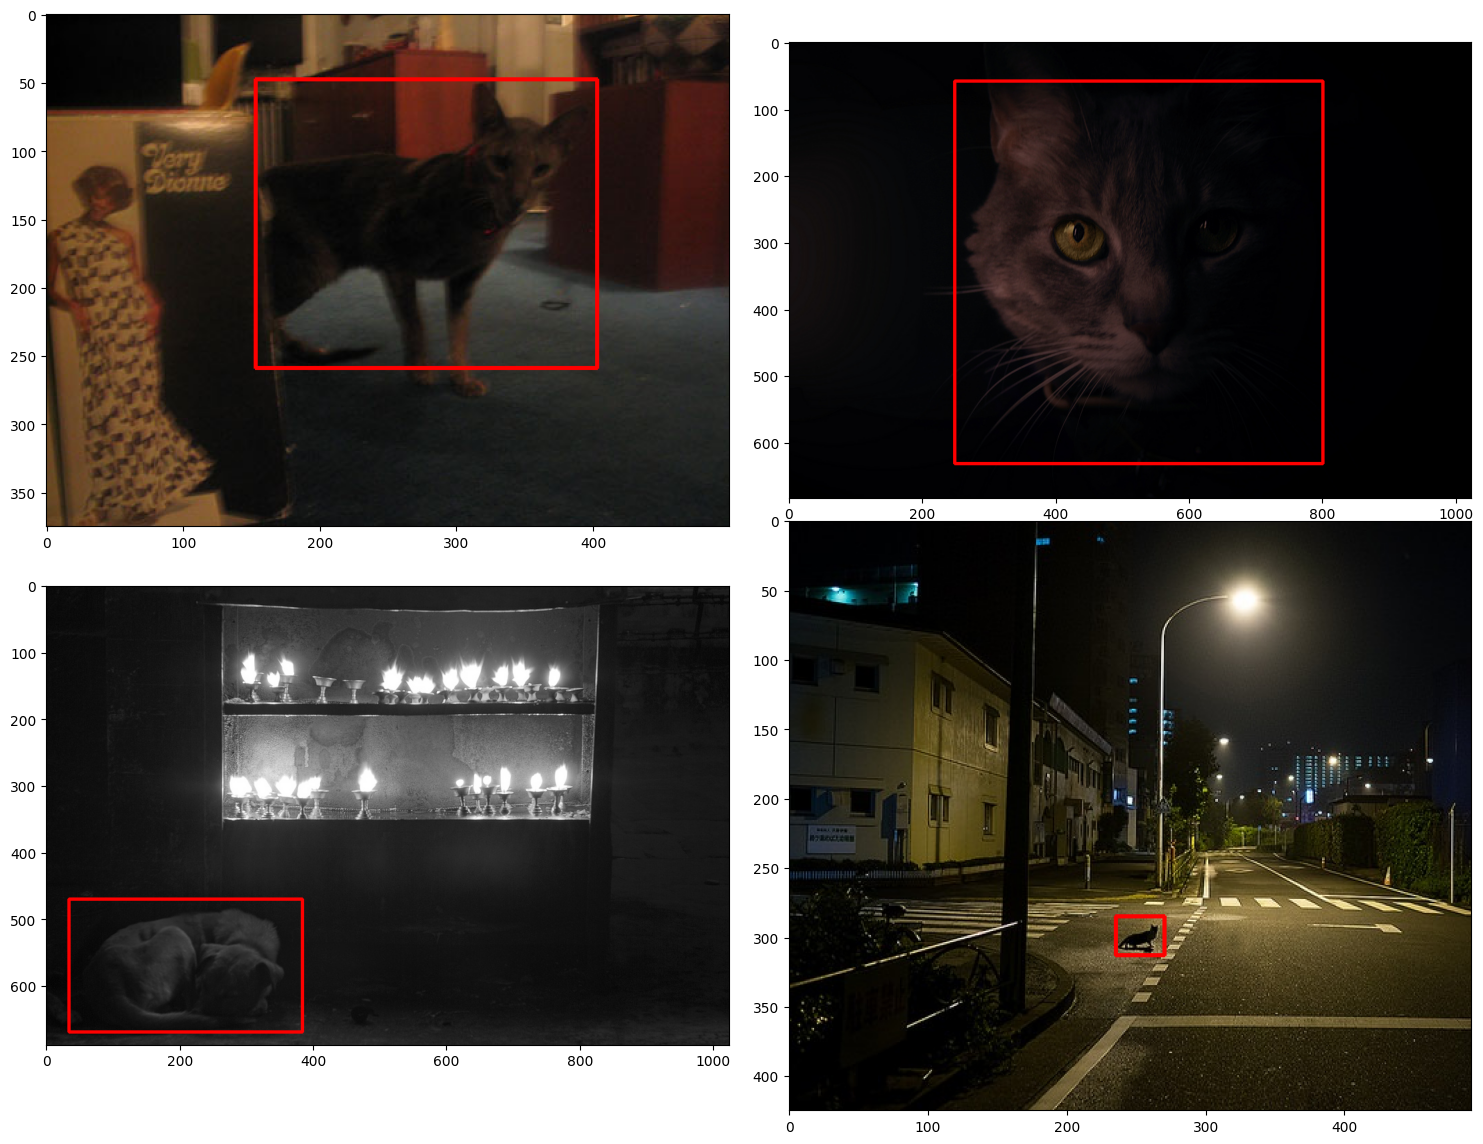

In [ ]:
# Visualize a few training images.
plot(
    image_paths='/content/Dataset/Cat_And_Dog_Detection/training/images',
    label_paths='/content/Dataset/Cat_And_Dog_Detection/training/labels',
    num_samples=4,
)

In [ ]:
%%writefile dataset.yaml
path: '/content/Dataset'
train: '/content/Dataset/Cat_And_Dog_Detection/training/images'
val: '/content/Dataset/Cat_And_Dog_Detection/val/images'

# class names
names:
  0: 'Cat'
  1: 'Dog'

nc: 2

Writing dataset.yaml


In [ ]:
!ls -l /content/Dataset/Cat_And_Dog_Detection/training/images | wc -l

401


In [ ]:
#Tuning the YOLOv8 Model
!yolo task=detect mode=train model=yolov8m.pt imgsz=1280 data=dataset.yaml epochs=25 batch=10 name=catdogdetection_model_1X

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=detect, mode=train, model=yolov8m.pt, data=dataset.yaml, epochs=25, time=None, patience=100, batch=10, imgsz=1280, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=catdogdetection_model_1X3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, m

In [ ]:
!yolo task=detect mode=val model=/content/drive/MyDrive/Dataset/runs/detect/catdogdetection_model_1X3/weights/best.pt data=dataset.yaml

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 218 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs
val: Scanning /content/Dataset/Cat_And_Dog_Detection/val/labels.cache... 200 images, 3 backgrounds, 0 corrupt: 100% 200/200 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 13/13 [00:16<00:00,  1.29s/it]
                   all        200        238      0.381      0.487      0.371      0.182
                   Cat         98        111      0.334      0.438       0.29      0.148
                   Dog         99        127      0.428      0.535      0.452      0.216
Speed: 7.6ms preprocess, 64.2ms inference, 0.0ms loss, 5.9ms postprocess per image
Results saved to runs/detect/val2
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
#Tuning the YOLOv8 Model
!yolo task=detect mode=train model=yolov8n.pt imgsz=1280 data=dataset.yaml epochs=25 batch=10 name=catdogdetection_model_1N

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=dataset.yaml, epochs=25, time=None, patience=100, batch=10, imgsz=1280, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=catdogdetection_model_1N, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show

In [ ]:
!yolo task=detect mode=val model=/content/drive/MyDrive/Dataset/runs/detect/catdogdetection_model_1N/weights/best.pt data=dataset.yaml

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 168 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Scanning /content/Dataset/Cat_And_Dog_Detection/val/labels.cache... 200 images, 3 backgrounds, 0 corrupt: 100% 200/200 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 13/13 [00:08<00:00,  1.56it/s]
                   all        200        238      0.497      0.468      0.494       0.26
                   Cat         98        111      0.422      0.423      0.434      0.232
                   Dog         99        127      0.572      0.512      0.554      0.288
Speed: 10.1ms preprocess, 12.2ms inference, 0.0ms loss, 6.3ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
#Tuning the YOLOv8 Model
!yolo task=detect mode=train model=yolov8s.pt imgsz=1280 data=dataset.yaml epochs=25 batch=10 name=catdogdetection_model_1S

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.43 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=dataset.yaml, epochs=25, time=None, patience=100, batch=10, imgsz=1280, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=catdogdetection_model_1S, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, ma

In [ ]:
!yolo task=detect mode=val model=/content/drive/MyDrive/Dataset/runs/detect/catdogdetection_model_1S/weights/best.pt data=dataset.yaml

Ultralytics 8.3.43 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 168 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Scanning /content/Dataset/Cat_And_Dog_Detection/val/labels.cache... 200 images, 3 backgrounds, 0 corrupt: 100% 200/200 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 13/13 [00:08<00:00,  1.51it/s]
                   all        200        238      0.414      0.483       0.43      0.218
                   Cat         98        111      0.378      0.486       0.38        0.2
                   Dog         99        127       0.45       0.48       0.48      0.237
Speed: 7.0ms preprocess, 26.1ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val
